# NOTEBOOK 02: PHÂN TÍCH KHÁM PHÁ (EDA) & CHIA TẬP TRAIN / DEV / TEST

**Dự án:** Hệ thống Cảnh báo sớm Học vụ và Mô phỏng Kịch bản Học tập 2 Tầng (What-If Simulator)

**Mục tiêu Notebook 2:**
- **Task 2.1:** Khám phá dữ liệu qua 4 biểu đồ trọng tâm (xuất ảnh chất lượng cao 300 DPI vào `reports/figures/`), kiểm chứng bằng trực quan tính hiệu quả của 3 biến đặc trưng tín chỉ Việt Nam vừa tạo.
- **Task 2.2:** Thực hiện chia tập dữ liệu chuẩn mực **70% Train - 15% Dev - 15% Test** (Stratified Split chống lệch nhãn), cố định dữ liệu vào `data/splits/` để phục vụ huấn luyện và đánh giá khách quan.

---
## 📊 EPIC 2: PHÂN TÍCH KHÁM PHÁ (EDA)
### 🔹 Task 2.1: Vẽ 4 Biểu đồ EDA Cốt lõi & Kiểm chứng Hiệu quả của 3 Biến Mới

Bốn biểu đồ đóng vai trò là bằng chứng khoa học cho cuốn báo cáo đồ án:
1. **Biểu đồ 1 (Tầng 1):** Tỷ lệ phân bố nhãn `is_dropout` (Căn cứ giải thích lý do cần SMOTE ở Tầng 1).
2. **Biểu đồ 2 (Tầng 1):** Violin Plot kiểm chứng 3 biến mới (`weighted_final_score`, `gpa_credits`, `gap_process_exam`) giữa nhóm Bỏ học (1) và An toàn (0).
3. **Biểu đồ 3 (Tầng 2):** Heatmap ma trận tương quan giữa các yếu tố thói quen sinh hoạt và điểm thi cuối kỳ (thang điểm 10).
4. **Biểu đồ 4 (Tầng 2):** Tác động kết hợp của Giờ tự học & Giấc ngủ lên Điểm thi (phân loại 3 nhóm giấc ngủ và 2 ngưỡng điểm 6.0 & 6.5).

In [1]:
# CELL 1: Import thư viện và cấu hình hiển thị đồ thị
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Xác định PROJECT_ROOT linh hoạt (hoạt động chuẩn dù chạy từ root hay trong notebooks/)
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
FIGURES_DIR = os.path.join(PROJECT_ROOT, 'reports', 'figures')
PROCESSED_DIR = os.path.join(PROJECT_ROOT, 'data', 'processed')
SPLITS_DIR = os.path.join(PROJECT_ROOT, 'data', 'splits')

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(SPLITS_DIR, exist_ok=True)

# Cấu hình thẩm mỹ đồ thị chuẩn báo cáo nghiên cứu
sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.titlesize'] = 14

print("✅ Thiết lập môi trường trực quan hóa thành công!")
print(f"   PROJECT_ROOT: {PROJECT_ROOT}")
print(f"   Thư mục lưu ảnh báo cáo: {FIGURES_DIR}")


✅ Thiết lập môi trường trực quan hóa thành công!
   PROJECT_ROOT: D:\What-If Simulator
   Thư mục lưu ảnh báo cáo: D:\What-If Simulator\reports\figures


In [2]:
# CELL 2: Nạp 2 bảng Master đã qua tiền xử lý ở Notebook 1
df_s1 = pd.read_csv(os.path.join(PROCESSED_DIR, 'stage1_oulad_master.csv'))
df_s2 = pd.read_csv(os.path.join(PROCESSED_DIR, 'stage2_performance_master.csv'))

print(f"✅ Master Tầng 1 (OULAD): {df_s1.shape[0]:,} dòng x {df_s1.shape[1]} cột")
print(f"✅ Master Tầng 2 (Kaggle): {df_s2.shape[0]:,} dòng x {df_s2.shape[1]} cột")


✅ Master Tầng 1 (OULAD): 32,593 dòng x 29 cột
✅ Master Tầng 2 (Kaggle): 6,607 dòng x 21 cột


### 2.1.1. Biểu đồ 1: Phân bố nhãn Mục tiêu Tầng 1 (`is_dropout`)

- **Mục đích:** Khảo sát độ cân bằng giữa nhóm sinh viên hoàn thành môn học (`Pass`, `Distinction` = 0) và nhóm sinh viên rớt môn/bỏ học (`Fail`, `Withdrawn` = 1).

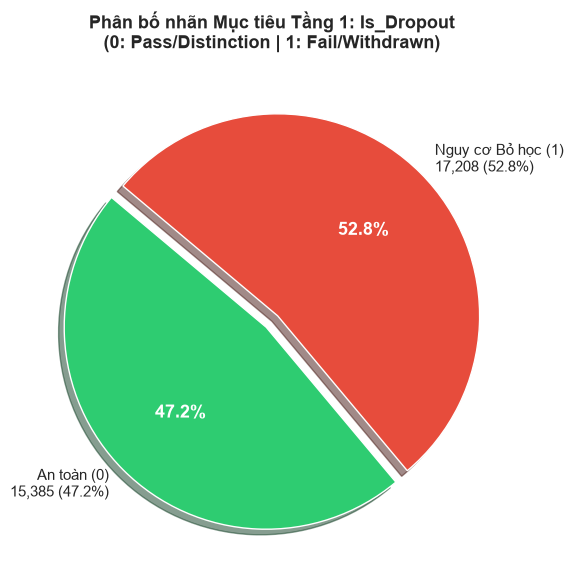

💾 Đã lưu ảnh chất lượng cao 300 DPI: D:\What-If Simulator\reports\figures\fig1_label_distribution.png


In [3]:
# CELL 3: Vẽ Biểu đồ 1 — Phân bố nhãn is_dropout (Pie Chart)
fig, ax = plt.subplots(figsize=(7, 6))
counts = df_s1['is_dropout'].value_counts().sort_index()
labels = [
    f"An toàn (0)\n{counts[0]:,} ({counts[0]/len(df_s1):.1%})",
    f"Nguy cơ Bỏ học (1)\n{counts[1]:,} ({counts[1]/len(df_s1):.1%})"
]
colors = ['#2ecc71', '#e74c3c']

wedges, texts, autotexts = ax.pie(
    counts,
    labels=labels,
    autopct='%1.1f%%',
    colors=colors,
    startangle=140,
    explode=(0.04, 0.04),
    shadow=True,
    textprops={'fontsize': 11}
)
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_weight('bold')
    autotext.set_fontsize(13)

ax.set_title('Phân bố nhãn Mục tiêu Tầng 1: Is_Dropout\n(0: Pass/Distinction | 1: Fail/Withdrawn)', fontsize=13, weight='bold', pad=15)
plt.tight_layout()

fig1_path = os.path.join(FIGURES_DIR, 'fig1_label_distribution.png')
plt.savefig(fig1_path, dpi=300)
plt.show()
print(f"💾 Đã lưu ảnh chất lượng cao 300 DPI: {fig1_path}")

### 2.1.2. Biểu đồ 2: Kiểm chứng Trực quan 3 Đặc trưng Tín chỉ Việt Nam

- **Mục đích:** Dùng Violin Plot để so sánh phân phối mật độ xác suất của 3 biến mới giữa 2 nhóm:
  1. `weighted_final_score`: Nhóm bỏ học tập trung ở mức điểm thấp < 4.0.
  2. `gpa_credits`: Nhóm bỏ học có GPA tín chỉ tích lũy thấp rõ rệt.
  3. `gap_process_exam`: Nhóm bỏ học có độ lệch dương lớn (đầu kỳ có làm bài nhưng cuối kỳ tụt dốc/bỏ nộp bài).

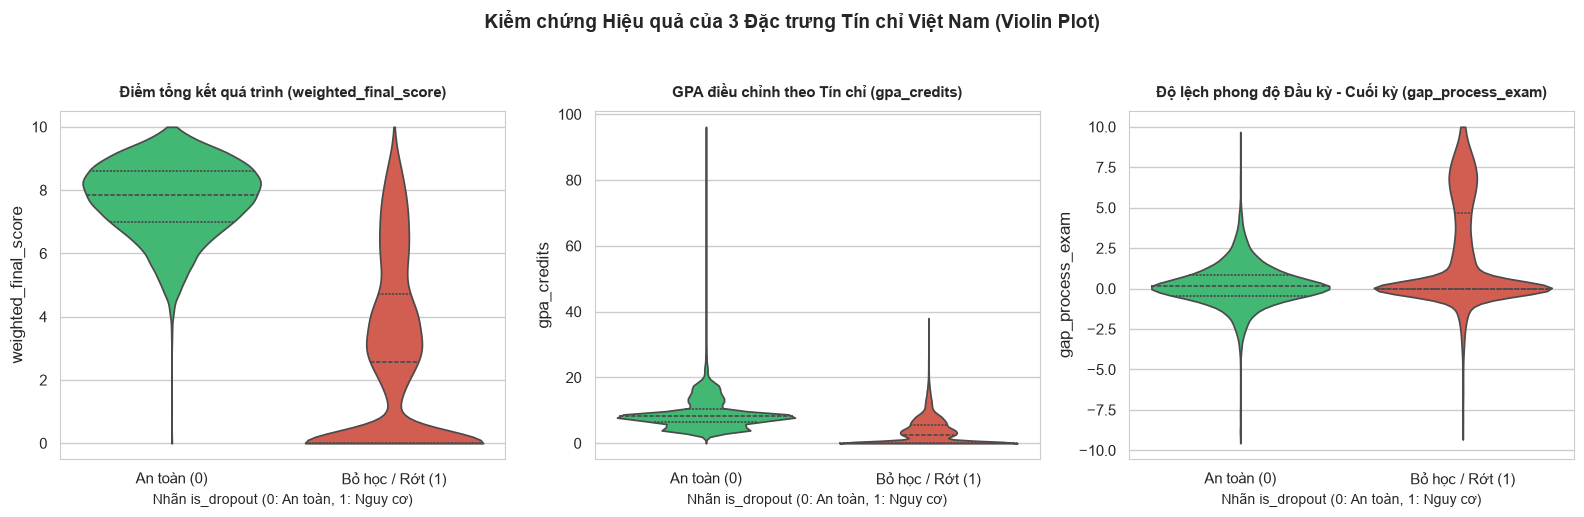

💾 Đã lưu ảnh chất lượng cao 300 DPI: D:\What-If Simulator\reports\figures\fig2_feature_validation_violin.png


In [4]:
# CELL 4: Vẽ Biểu đồ 2 — Violin Plot kiểm chứng 3 đặc trưng Tín chỉ VN
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
features_vn = ['weighted_final_score', 'gpa_credits', 'gap_process_exam']
titles = [
    'Điểm tổng kết quá trình (weighted_final_score)',
    'GPA điều chỉnh theo Tín chỉ (gpa_credits)',
    'Độ lệch phong độ Đầu kỳ - Cuối kỳ (gap_process_exam)'
]

for i, (feat, title) in enumerate(zip(features_vn, titles)):
    sns.violinplot(
        data=df_s1,
        x='is_dropout',
        y=feat,
        hue='is_dropout',
        palette=['#2ecc71', '#e74c3c'],
        legend=False,
        ax=axes[i],
        inner='quartile',
        cut=0
    )
    axes[i].set_title(title, fontsize=11, weight='bold', pad=10)
    axes[i].set_xlabel('Nhãn is_dropout (0: An toàn, 1: Nguy cơ)', fontsize=10)
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(['An toàn (0)', 'Bỏ học / Rớt (1)'])

plt.suptitle('Kiểm chứng Hiệu quả của 3 Đặc trưng Tín chỉ Việt Nam (Violin Plot)', fontsize=14, weight='bold', y=1.03)
plt.tight_layout()

fig2_path = os.path.join(FIGURES_DIR, 'fig2_feature_validation_violin.png')
plt.savefig(fig2_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"💾 Đã lưu ảnh chất lượng cao 300 DPI: {fig2_path}")

### 2.1.3. Biểu đồ 3: Heatmap Ma trận Tương quan Tầng 2 (Thang điểm 10)

- **Mục đích:** Đo lường mức độ tương quan tuyến tính giữa các thói quen học tập (`Hours_Studied`, `Sleep_Hours`, `Attendance`, `Previous_Scores`) với biến mục tiêu `Exam_Score`.

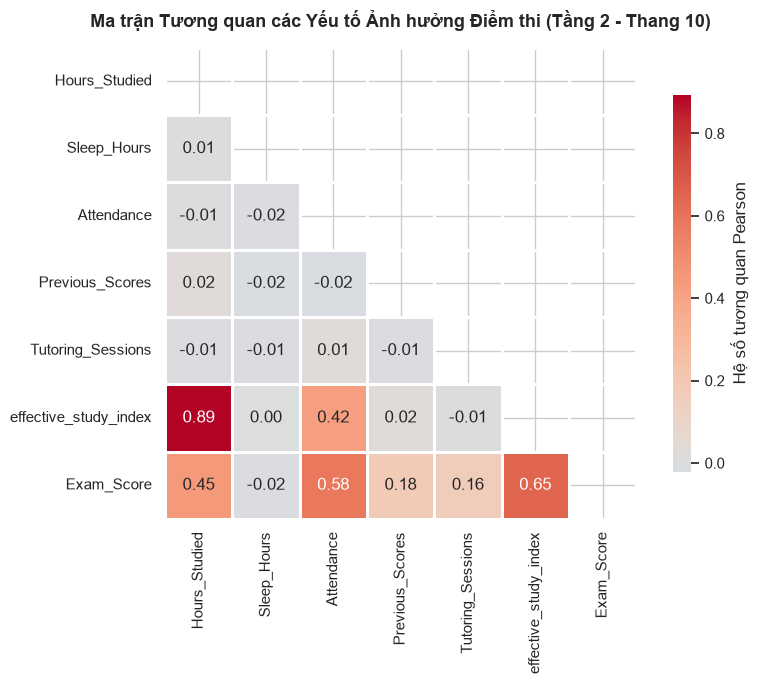

💾 Đã lưu ảnh chất lượng cao 300 DPI: D:\What-If Simulator\reports\figures\fig3_correlation_heatmap.png


In [5]:
# CELL 5: Vẽ Biểu đồ 3 — Heatmap ma trận tương quan Tầng 2
corr_cols = [
    'Hours_Studied', 'Sleep_Hours', 'Attendance',
    'Previous_Scores', 'Tutoring_Sessions', 'effective_study_index', 'Exam_Score'
]
corr_matrix = df_s2[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=1,
    cbar_kws={'shrink': 0.8, 'label': 'Hệ số tương quan Pearson'},
    ax=ax
)
ax.set_title('Ma trận Tương quan các Yếu tố Ảnh hưởng Điểm thi (Tầng 2 - Thang 10)', fontsize=13, weight='bold', pad=15)
plt.tight_layout()

fig3_path = os.path.join(FIGURES_DIR, 'fig3_correlation_heatmap.png')
plt.savefig(fig3_path, dpi=300)
plt.show()
print(f"💾 Đã lưu ảnh chất lượng cao 300 DPI: {fig3_path}")

### 2.1.4. Biểu đồ 4: Tác động Kết hợp của Giờ tự học & Giấc ngủ lên Điểm thi

- **Mục đích:** Khảo sát xem sinh viên thiếu ngủ ($\le 5h$), ngủ chuẩn (6 – 8h) hay ngủ nhiều ($> 8h$) đạt kết quả ra sao khi cùng tăng số giờ tự học mỗi tuần.

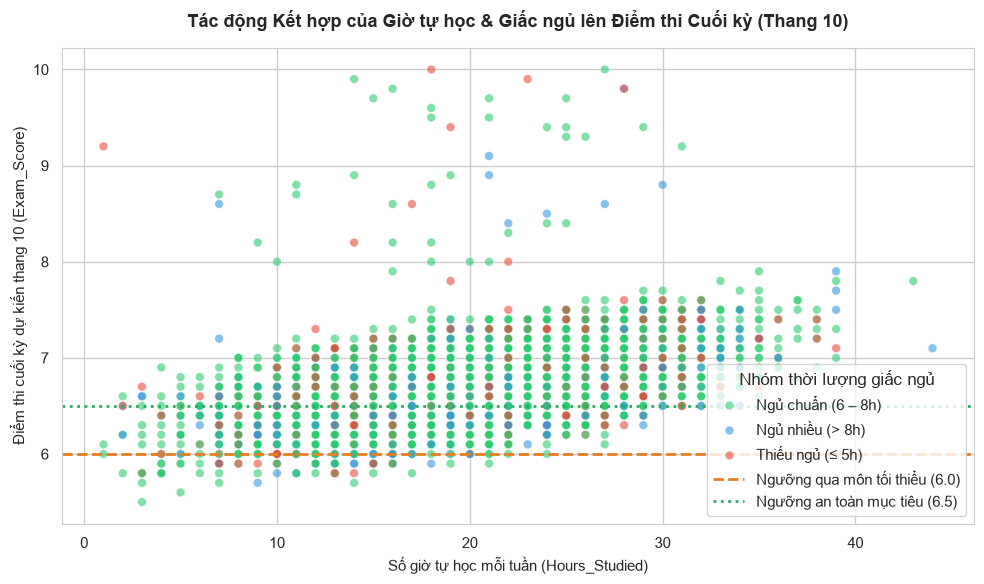

💾 Đã lưu ảnh chất lượng cao 300 DPI: D:\What-If Simulator\reports\figures\fig4_sleep_study_exam.png

🎉 TASK 2.1 CHECKPOINTS: TẤT CẢ 4 BIỂU ĐỒ EDA ĐỀU ĐẠT CHUẨN 300 DPI!
   📸 D:\What-If Simulator\reports\figures\fig1_label_distribution.png: 191.2 KB (Đạt chuẩn 300 DPI)
   📸 D:\What-If Simulator\reports\figures\fig2_feature_validation_violin.png: 320.1 KB (Đạt chuẩn 300 DPI)
   📸 D:\What-If Simulator\reports\figures\fig3_correlation_heatmap.png: 218.4 KB (Đạt chuẩn 300 DPI)
   📸 D:\What-If Simulator\reports\figures\fig4_sleep_study_exam.png: 536.6 KB (Đạt chuẩn 300 DPI)


In [6]:
# CELL 6: Vẽ Biểu đồ 4 — Scatter Plot Giờ học vs Điểm thi theo 3 nhóm Giấc ngủ
def categorize_sleep(hours):
    if hours <= 5.0:
        return 'Thiếu ngủ (≤ 5h)'
    elif hours <= 8.0:
        return 'Ngủ chuẩn (6 – 8h)'
    else:
        return 'Ngủ nhiều (> 8h)'

df_s2['sleep_group'] = df_s2['Sleep_Hours'].apply(categorize_sleep)

fig, ax = plt.subplots(figsize=(10, 6))
sleep_palette = {
    'Thiếu ngủ (≤ 5h)': '#e74c3c',
    'Ngủ chuẩn (6 – 8h)': '#2ecc71',
    'Ngủ nhiều (> 8h)': '#3498db'
}

sns.scatterplot(
    data=df_s2,
    x='Hours_Studied',
    y='Exam_Score',
    hue='sleep_group',
    palette=sleep_palette,
    alpha=0.6,
    s=40,
    ax=ax
)
ax.axhline(y=6.0, color='#e67e22', linestyle='--', linewidth=2, label='Ngưỡng qua môn tối thiểu (6.0)')
ax.axhline(y=6.5, color='#27ae60', linestyle=':', linewidth=2, label='Ngưỡng an toàn mục tiêu (6.5)')

ax.set_title('Tác động Kết hợp của Giờ tự học & Giấc ngủ lên Điểm thi Cuối kỳ (Thang 10)', fontsize=13, weight='bold', pad=15)
ax.set_xlabel('Số giờ tự học mỗi tuần (Hours_Studied)', fontsize=11)
ax.set_ylabel('Điểm thi cuối kỳ dự kiến thang 10 (Exam_Score)', fontsize=11)
ax.legend(title='Nhóm thời lượng giấc ngủ', loc='lower right', frameon=True)
plt.tight_layout()

fig4_path = os.path.join(FIGURES_DIR, 'fig4_sleep_study_exam.png')
plt.savefig(fig4_path, dpi=300)
plt.show()
print(f"💾 Đã lưu ảnh chất lượng cao 300 DPI: {fig4_path}")

# ============================================================
# CHECKPOINTS KIỂM ĐỊNH CHẤT LƯỢNG (ACCEPTANCE CRITERIA)
# ============================================================
for p in [fig1_path, fig2_path, fig3_path, fig4_path]:
    assert os.path.exists(p), f"❌ Lỗi: Thiếu file biểu đồ {p}!"
    size_kb = os.path.getsize(p) / 1024
    assert size_kb > 50.0, f"❌ Lỗi: File ảnh {p} quá nhỏ ({size_kb:.1f} KB), có thể bị lỗi khi render!"

print("\n" + "="*60)
print("🎉 TASK 2.1 CHECKPOINTS: TẤT CẢ 4 BIỂU ĐỒ EDA ĐỀU ĐẠT CHUẨN 300 DPI!")
for p in [fig1_path, fig2_path, fig3_path, fig4_path]:
    print(f"   📸 {p}: {os.path.getsize(p)/1024:.1f} KB (Đạt chuẩn 300 DPI)")
print("="*60)

---
### 🔹 Task 2.2: Chia tập Train (70%) / Dev (15%) / Test (15%) cho Tầng 1 và Tầng 2

**Nguyên tắc Kỹ thuật Machine Learning Chống Học Vẹt & Rò Rỉ Dữ liệu:**
1. **Vì sao chia 3 tập (Train / Dev / Test) thay vì 2 tập thông thường?**
   - **Tập Train (70%):** Dùng để huấn luyện thuật toán và fit bộ biến đổi (`StandardScaler`, `SMOTE`).
   - **Tập Dev (15% - Development / Validation Set):** Dùng để tinh chỉnh siêu tham số (`GridSearchCV`), tìm ngưỡng cắt tối ưu (`optimal_threshold`), vẽ đồ thị phần dư (Residual Plot) và trích xuất các ca lỗi (`FN`, `FP`, `Top 20 Outliers`) phục vụ phân tích chuyên sâu.
   - **Tập Test (15% - Unseen Test Set):** Giữ nguyên tinh khiết 100%, **tuyệt đối không dùng để chọn mô hình hay chỉnh ngưỡng**. Chỉ mở ra đánh giá đúng 1 lần duy nhất khi đóng gói bàn giao.

2. **Kỹ thuật Phân tầng (Stratified Splitting chống lệch phân phối):**
   - **Ở Tầng 1 (Phân loại):** Dùng `stratify=y` qua 2 bước tách `train_test_split(random_state=42)` để giữ nguyên tỷ lệ nhãn `is_dropout` ở cả 3 tập xấp xỉ 52.8%.
   - **Ở Tầng 2 (Hồi quy):** Dùng phân vị 5 nhóm (`pd.qcut(q=5)`) để phân tầng, đảm bảo phân phối điểm thi `Exam_Score` ở cả 3 tập đều đạt mức trung bình 6.72/10.

3. **Đầu ra:** Cố định 6 file CSV độc lập vào thư mục `data/splits/`.

In [7]:
# CELL 7: Chia tập Tầng 1 — Stratified Split 70% Train / 15% Dev / 15% Test & Tách Dev Blackbox/Eyeball
from sklearn.model_selection import train_test_split

SPLITS_DIR = os.path.join(PROJECT_ROOT, 'data', 'splits')
os.makedirs(SPLITS_DIR, exist_ok=True)

# Danh sách 10 đặc trưng chính Tầng 1 (Đã loại trừ date_unregistration để chống Target Leakage)
FEATURES_T1 = [
    'weighted_final_score', 'gpa_credits', 'gap_process_exam',
    'submitted_count', 'attendance_rate', 'total_clicks',
    'num_of_prev_attempts', 'studied_credits',
    'vle_engagement_score', 'vle_drop_ratio'
]
TARGET_T1 = 'is_dropout'

X1 = df_s1[FEATURES_T1]
y1 = df_s1[TARGET_T1]

# Bước 1: Tách 70% Train và 30% Temp (bắt buộc dùng stratify=y1)
X1_train, X1_temp, y1_train, y1_temp = train_test_split(
    X1, y1, test_size=0.30, random_state=42, stratify=y1
)

# Bước 2: Chia đôi 30% Temp thành 15% Dev và 15% Test (stratify=y1_temp)
X1_dev, X1_test, y1_dev, y1_test = train_test_split(
    X1_temp, y1_temp, test_size=0.50, random_state=42, stratify=y1_temp
)

# Bước 3: Phân chia tập Dev thành 70% Blackbox và 30% Eyeball (stratify=y1_dev)
X1_dev_bb, X1_dev_eye, y1_dev_bb, y1_dev_eye = train_test_split(
    X1_dev, y1_dev, test_size=0.30, random_state=42, stratify=y1_dev
)

# Ghép đặc trưng và nhãn để lưu ra CSV cố định
train1_df        = pd.concat([X1_train,   y1_train],   axis=1)
dev1_df          = pd.concat([X1_dev,     y1_dev],     axis=1)
dev1_blackbox_df = pd.concat([X1_dev_bb,  y1_dev_bb],  axis=1)
dev1_eyeball_df  = pd.concat([X1_dev_eye, y1_dev_eye], axis=1)
test1_df         = pd.concat([X1_test,    y1_test],    axis=1)

train1_df.to_csv(os.path.join(SPLITS_DIR, 'stage1_train.csv'), index=False)
dev1_df.to_csv(os.path.join(SPLITS_DIR, 'stage1_dev.csv'), index=False)
dev1_blackbox_df.to_csv(os.path.join(SPLITS_DIR, 'stage1_dev_blackbox.csv'), index=False)
dev1_eyeball_df.to_csv(os.path.join(SPLITS_DIR, 'stage1_dev_eyeball.csv'), index=False)
test1_df.to_csv(os.path.join(SPLITS_DIR, 'stage1_test.csv'), index=False)

print("✅ Chia tập Tầng 1 hoàn tất (Phân tầng Stratified):")
print(f"   📦 Train (70%):            {len(train1_df):,} dòng | Tỷ lệ nguy cơ bỏ học: {y1_train.mean():.4f}")
print(f"   📦 Dev Tổng (15%):         {len(dev1_df):,} dòng | Tỷ lệ nguy cơ bỏ học: {y1_dev.mean():.4f}")
print(f"      🔹 Dev Blackbox (70%):  {len(dev1_blackbox_df):,} dòng | Tỷ lệ nguy cơ: {y1_dev_bb.mean():.4f}")
print(f"      🔹 Dev Eyeball (30%):   {len(dev1_eyeball_df):,} dòng | Tỷ lệ nguy cơ: {y1_dev_eye.mean():.4f}")
print(f"   📦 Test (15%):             {len(test1_df):,} dòng | Tỷ lệ nguy cơ bỏ học: {y1_test.mean():.4f}")


✅ Chia tập Tầng 1 hoàn tất (Phân tầng Stratified):
   📦 Train (70%):            22,815 dòng | Tỷ lệ nguy cơ bỏ học: 0.5280
   📦 Dev Tổng (15%):         4,889 dòng | Tỷ lệ nguy cơ bỏ học: 0.5279
      🔹 Dev Blackbox (70%):  3,422 dòng | Tỷ lệ nguy cơ: 0.5281
      🔹 Dev Eyeball (30%):   1,467 dòng | Tỷ lệ nguy cơ: 0.5276
   📦 Test (15%):             4,889 dòng | Tỷ lệ nguy cơ bỏ học: 0.5279


In [8]:
# CELL 8: Chia tập Tầng 2 — Phân vị điểm Quantile Stratified Split 70/15/15 & Tách Dev Blackbox/Eyeball
# Lưu đầy đủ các biến gồm Nhóm Hành vi (Actionable) và Nhóm Ngữ cảnh (Fixed Context)
FEATURES_T2 = [col for col in df_s2.columns if col != 'Exam_Score']
TARGET_T2 = 'Exam_Score'

X2 = df_s2[FEATURES_T2]
y2 = df_s2[TARGET_T2]

# Phân tầng bài toán Hồi quy bằng 5 phân vị điểm số (Quantile Bins)
y2_bins = pd.qcut(y2, q=5, labels=False)

# Bước 1: Tách 70% Train và 30% Temp
X2_train, X2_temp, y2_train, y2_temp, bins_train, bins_temp = train_test_split(
    X2, y2, y2_bins, test_size=0.30, random_state=42, stratify=y2_bins
)

# Bước 2: Chia đôi 30% Temp thành 15% Dev và 15% Test
X2_dev, X2_test, y2_dev, y2_test, bins_dev, bins_test = train_test_split(
    X2_temp, y2_temp, bins_temp, test_size=0.50, random_state=42, stratify=bins_temp
)

# Bước 3: Phân chia tập Dev thành 70% Blackbox và 30% Eyeball (stratify=bins_dev)
X2_dev_bb, X2_dev_eye, y2_dev_bb, y2_dev_eye = train_test_split(
    X2_dev, y2_dev, test_size=0.30, random_state=42, stratify=bins_dev
)

train2_df        = pd.concat([X2_train,   y2_train],   axis=1)
dev2_df          = pd.concat([X2_dev,     y2_dev],     axis=1)
dev2_blackbox_df = pd.concat([X2_dev_bb,  y2_dev_bb],  axis=1)
dev2_eyeball_df  = pd.concat([X2_dev_eye, y2_dev_eye], axis=1)
test2_df         = pd.concat([X2_test,    y2_test],    axis=1)

train2_df.to_csv(os.path.join(SPLITS_DIR, 'stage2_train.csv'), index=False)
dev2_df.to_csv(os.path.join(SPLITS_DIR, 'stage2_dev.csv'), index=False)
dev2_blackbox_df.to_csv(os.path.join(SPLITS_DIR, 'stage2_dev_blackbox.csv'), index=False)
dev2_eyeball_df.to_csv(os.path.join(SPLITS_DIR, 'stage2_dev_eyeball.csv'), index=False)
test2_df.to_csv(os.path.join(SPLITS_DIR, 'stage2_test.csv'), index=False)

print("✅ Chia tập Tầng 2 hoàn tất (Phân tầng Quantile Bins, lưu đủ biến Hành vi & Ngữ cảnh):")
print(f"   📦 Train (70%):            {len(train2_df):,} dòng x {train2_df.shape[1]} cột | Điểm thi TB: {y2_train.mean():.4f}/10")
print(f"   📦 Dev Tổng (15%):         {len(dev2_df):,} dòng x {dev2_df.shape[1]} cột | Điểm thi TB: {y2_dev.mean():.4f}/10")
print(f"      🔹 Dev Blackbox (70%):  {len(dev2_blackbox_df):,} dòng x {dev2_blackbox_df.shape[1]} cột | Điểm thi: {y2_dev_bb.mean():.4f}/10")
print(f"      🔹 Dev Eyeball (30%):   {len(dev2_eyeball_df):,} dòng x {dev2_eyeball_df.shape[1]} cột | Điểm thi: {y2_dev_eye.mean():.4f}/10")
print(f"   📦 Test (15%):             {len(test2_df):,} dòng x {test2_df.shape[1]} cột | Điểm thi TB: {y2_test.mean():.4f}/10")


✅ Chia tập Tầng 2 hoàn tất (Phân tầng Quantile Bins, lưu đủ biến Hành vi & Ngữ cảnh):
   📦 Train (70%):            4,624 dòng x 22 cột | Điểm thi TB: 6.7245/10
   📦 Dev Tổng (15%):         991 dòng x 22 cột | Điểm thi TB: 6.7222/10
      🔹 Dev Blackbox (70%):  693 dòng x 22 cột | Điểm thi: 6.7192/10
      🔹 Dev Eyeball (30%):   298 dòng x 22 cột | Điểm thi: 6.7292/10
   📦 Test (15%):             992 dòng x 22 cột | Điểm thi TB: 6.7205/10


In [9]:
# CELL 9: Kiểm định Chất lượng Toàn diện cho cả 10 tập dữ liệu (Acceptance Criteria)
# 1. Kiểm tra toàn vẹn tổng số dòng
assert len(train1_df) + len(dev1_df) + len(test1_df) == len(df_s1), "❌ Lỗi: Tổng số dòng Tầng 1 không khớp!"
assert len(train2_df) + len(dev2_df) + len(test2_df) == len(df_s2), "❌ Lỗi: Tổng số dòng Tầng 2 không khớp!"
assert len(dev1_blackbox_df) + len(dev1_eyeball_df) == len(dev1_df), "❌ Lỗi: Tổng Blackbox + Eyeball Tầng 1 không khớp Dev!"
assert len(dev2_blackbox_df) + len(dev2_eyeball_df) == len(dev2_df), "❌ Lỗi: Tổng Blackbox + Eyeball Tầng 2 không khớp Dev!"

# 2. Kiểm tra độ lệch tỷ lệ nhãn Tầng 1 (sai lệch < 0.1% giữa Train và Dev)
diff_dev_t1  = abs(y1_train.mean() - y1_dev.mean())
diff_test_t1 = abs(y1_train.mean() - y1_test.mean())
diff_bb_t1   = abs(y1_train.mean() - y1_dev_bb.mean())
assert diff_dev_t1 < 0.001, f"❌ Lỗi: Lệch tỷ lệ nhãn Train-Dev Tầng 1: {diff_dev_t1:.4f}"
assert diff_test_t1 < 0.001, f"❌ Lỗi: Lệch tỷ lệ nhãn Train-Test Tầng 1: {diff_test_t1:.4f}"
assert diff_bb_t1 < 0.005, f"❌ Lỗi: Lệch tỷ lệ nhãn Train-Dev Blackbox Tầng 1: {diff_bb_t1:.4f}"

# 3. Kiểm tra độ lệch trung bình điểm Tầng 2 (sai lệch < 0.05 điểm)
diff_dev_t2  = abs(y2_train.mean() - y2_dev.mean())
diff_test_t2 = abs(y2_train.mean() - y2_test.mean())
assert diff_dev_t2 < 0.05, f"❌ Lỗi: Lệch điểm thi Train-Dev Tầng 2: {diff_dev_t2:.4f}"
assert diff_test_t2 < 0.05, f"❌ Lỗi: Lệch điểm thi Train-Test Tầng 2: {diff_test_t2:.4f}"

# 4. Kiểm tra tồn tại 10 file CSV trên ổ cứng
expected_files = [
    'stage1_train.csv', 'stage1_dev.csv', 'stage1_dev_blackbox.csv', 'stage1_dev_eyeball.csv', 'stage1_test.csv',
    'stage2_train.csv', 'stage2_dev.csv', 'stage2_dev_blackbox.csv', 'stage2_dev_eyeball.csv', 'stage2_test.csv'
]
for fname in expected_files:
    fpath = os.path.join(SPLITS_DIR, fname)
    assert os.path.exists(fpath), f"❌ Lỗi: Thiếu file split {fpath}!"

print("\n" + "="*60)
print("🎉 TASK 2.2 CHECKPOINTS: TẤT CẢ 10 TẬP DỮ LIỆU ĐỀU ĐẠT CHUẨN XUẤT SẮC!")
for fname in expected_files:
    fpath = os.path.join(SPLITS_DIR, fname)
    size_kb = os.path.getsize(fpath) / 1024
    line_cnt = len(pd.read_csv(fpath))
    print(f"   💾 {fname:<25}: {line_cnt:>6,} dòng | {size_kb:>7.1f} KB")
print("="*60)
print("\n🏆 CHÚC MỪNG BẠN ĐÃ HOÀN THÀNH 100% EPIC 2 (NOTEBOOK 02)! 🏆")



🎉 TASK 2.2 CHECKPOINTS: TẤT CẢ 10 TẬP DỮ LIỆU ĐỀU ĐẠT CHUẨN XUẤT SẮC!
   💾 stage1_train.csv         : 22,815 dòng |  1092.2 KB


   💾 stage1_dev.csv           :  4,889 dòng |   234.2 KB
   💾 stage1_dev_blackbox.csv  :  3,422 dòng |   164.0 KB


   💾 stage1_dev_eyeball.csv   :  1,467 dòng |    70.5 KB


   💾 stage1_test.csv          :  4,889 dòng |   234.2 KB


   💾 stage2_train.csv         :  4,624 dòng |   583.0 KB
   💾 stage2_dev.csv           :    991 dòng |   125.2 KB
   💾 stage2_dev_blackbox.csv  :    693 dòng |    87.6 KB
   💾 stage2_dev_eyeball.csv   :    298 dòng |    37.9 KB


   💾 stage2_test.csv          :    992 dòng |   125.4 KB

🏆 CHÚC MỪNG BẠN ĐÃ HOÀN THÀNH 100% EPIC 2 (NOTEBOOK 02)! 🏆
